# 16 · 정규화 층: 어느 축을 평균내고 무엇을 미분할까

**이번 질문:** 은닉층 값의 중심과 크기를 조절하려면 어느 값들끼리 묶어야 할까요? 그 평균과 분산도 입력에서 계산했는데, 역전파에서는 어떻게 다뤄야 할까요?

작은 표에서 손으로 평균과 분산을 구한 뒤, BatchNorm·LayerNorm·RMSNorm을 NumPy로 만듭니다. 구조, 미분, 학습 중 통계, 평가 때의 사용 규칙을 따로 확인하고 같은 MNIST 분류기에 넣어 비교합니다.

- 준비물: [00](../00_기초/00_math_to_numpy.ipynb)의 배열·축·브로드캐스팅, [01](../00_기초/01_gradients_and_learning.ipynb)의 중심차분과 연쇄법칙, [01b](../00_기초/01b_minibatch.ipynb)의 배치, [03](../00_기초/03_perceptron_to_mlp.ipynb)의 MLP, [04](../00_기초/04_optimizers.ipynb)의 Momentum입니다.
- 도착점: 축과 ε → BatchNorm의 train/eval → LayerNorm → RMSNorm과 경계 조건 → 같은 MLP의 독립 평가입니다.
- 다음 연결: CNN에 정규화를 추가할 때의 축 선택 기준을 익히고 [17 ResNet](17_resnet.ipynb)·[18 U-Net](18_unet.ipynb)의 구조 조합으로 넘어갑니다. 두 후속 노트북은 구조 자체를 보기 위해 정규화 층을 생략합니다. [09 Transformer](../01_아키텍처/09_transformer.ipynb)의 토큰별 정규화와도 축을 비교합니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·설명·구현 | 축과 shape를 적으며 다시 구성합니다 |
| 🔍 확인 | 그림 해석·검산 | 주장과 실제 숫자를 대조합니다 |
| 📎 참고 | 환경·관용구·연결 | 필요할 때 돌아옵니다 |
| ✏️ 연습 | 핵심 한두 줄 채우기 | 손계산한 뒤 검사 셀을 실행합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 정규화의 첫 질문은 **어느 축을 묶는가**입니다. `(N,D)`에서 BN은 표본 축, LN·RMS는 특징 축으로 통계를 냅니다.
2. 학습 중 계산한 평균·분산은 입력의 함수이므로 미분 경로가 있습니다. BN 평가에서는 저장한 통계가 상수여서 입력 기울기가 달라집니다.
3. ε가 있으면 정규화 분산은 항상 정확히 1이 아니며, 양의 배율 변화에 대한 불변성도 보통 근사입니다. 학습이 잘 되는지는 고정 조건의 실험으로 확인합니다.

| 기호 | shape | 의미 |
|---|---|---|
| $X,Y,G$ | $(N,D)$ | 정규화 입력·출력·출력에 대한 손실 기울기 |
| $\gamma,\beta$ | $(D,)$ | 특징별 학습 가능한 배율과 이동량 |
| $\mu,v$ | BN: $(1,D)$ / LN: $(N,1)$ | 묶은 축의 평균·분산 |
| $\widehat X$ | $(N,D)$ | 중심과 크기를 조절한 값, affine 변환 전 |
| $\epsilon$ | 스칼라 양수 | 분모가 0이 되는 것을 막는 수치 상수 |

[그림 보조 코드](../../src/utils/normalization_plots.py) · [학습 경로](../../docs/CURRICULUM.md) · [글 규칙](../../docs/WRITING.md)

📎 **준비와 코드 표기**

실행에는 NumPy·Matplotlib·Jupyter가 필요합니다. 손계산에서 시작해 작은 MNIST 분류 실험으로 이어집니다. **MNIST**는 28×28 화소의 손글씨 숫자 0–9 자료입니다. 잉크 양을 0–1로 나타내고, 784개 값으로 펼칩니다. 그림에는 프로젝트 전체에서 같은 `load_examples(download=True)`의 예시를 씁니다.

> **코드** · `axis=0`은 행 방향(표본)을 평균하고, `axis=1`은 열 방향(특징)을 평균합니다. `keepdims=True`는 평균한 축을 길이 1로 남겨 뺄셈할 때 원래 shape에 맞게 펼칩니다. `@`는 행렬 곱, `*`는 같은 위치끼리 곱입니다. `rng.normal(size=...)`은 정해 둔 난수 생성기에서 정규분포 표본을 만듭니다.

수치미분은 float64와 중심차분 간격 $10^{-6}$을 사용합니다. 정규화의 기본 ε는 $10^{-5}$입니다. 개념 그림에서는 ε의 효과를 잘 보이게 다른 값을 명시하기도 합니다. 작은 행렬 연산의 스레드 비용이 크면 커널 시작 전 `OPENBLAS_NUM_THREADS=1`, `OMP_NUM_THREADS=1`을 지정할 수 있습니다.

In [1]:
# 준비 셀: 프로젝트 경로와 공통 도구를 불러옵니다.
import sys
from pathlib import Path
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
from time import perf_counter
from src.utils import setup_plots, run_check
from src.utils.gradcheck import numerical_gradient, rel_error
from src.data.mnist import load_mnist, load_examples
from src.utils.normalization_plots import (
    plot_axis_normalization, plot_bn_modes, plot_batch_independence,
    plot_norm_comparison, plot_mlp_norm_flow, plot_norm_training, plot_norm_predictions,
)
setup_plots()
print("NumPy", np.__version__, "· 정규화 층 준비 완료")

NumPy 2.4.6 · 정규화 층 준비 완료


## 🔑 1. 어느 값들끼리 평균과 분산을 구할까

**이 절에서 가져갈 것:** 작은 행렬의 열을 정규화하고, 손계산·반복문·벡터화가 같은 결과인지 확인합니다.

어떤 은닉 유닛의 값은 $1,3$이고 다른 유닛의 값은 $10,14$라고 합시다. 평균을 빼면 각각 $-1,1$과 $-2,2$가 됩니다. 중심은 같아졌지만 크기는 아직 다릅니다. 각 열의 표준편차로 나누면 크기도 조절할 수 있습니다.

> **용어** · **정규화(normalization)**는 정한 묶음의 중심이나 크기를 일정한 규칙으로 조절하는 연산입니다. 여기서 **분산**은 평균을 뺀 값의 제곱 평균이며, 묶음 크기 $M$으로 나눕니다. **표준편차**는 그 제곱근입니다. 가중치 벌점 등의 **정칙화(regularization)**와는 다른 연산입니다.

묶음 안 값이 $x_1,\dots,x_M$이면

$$\mu=\frac1M\sum_i x_i,\quad v=\frac1M\sum_i(x_i-\mu)^2,\quad r=\frac1{\sqrt{v+\epsilon}},\quad \widehat x_i=(x_i-\mu)r.$$

평균을 빼고, 분산에 ε를 더한 값의 제곱근으로 나눕니다. 따라서

$$\operatorname{mean}(\widehat x)=0,\qquad \operatorname{var}(\widehat x)=\frac{v}{v+\epsilon}.$$

분산이 ε에 비해 클 때만 1에 가깝습니다. 상수 입력이면 $v=0$이고 결과는 0입니다. 손계산에서는

$$X=\begin{bmatrix}1&10\\3&14\end{bmatrix},\quad \mu=(2,12),\quad v=(1,4).$$

그림에서는 $\epsilon=1$로 두어 분산이 $1/2,4/5$가 되는 차이를 보겠습니다. 실제 학습의 기본 ε는 훨씬 작습니다.

In [2]:
# 그림 계산: 두 행은 표본, 두 열은 서로 다른 은닉 유닛입니다.
axis_x = np.array([[1., 10.], [3., 14.]])
axis_mean = np.mean(axis_x, axis=0, keepdims=True)
axis_centered = axis_x - axis_mean
axis_var = np.mean(axis_centered ** 2, axis=0, keepdims=True)
axis_normalized = axis_centered / np.sqrt(axis_var + 1.0)

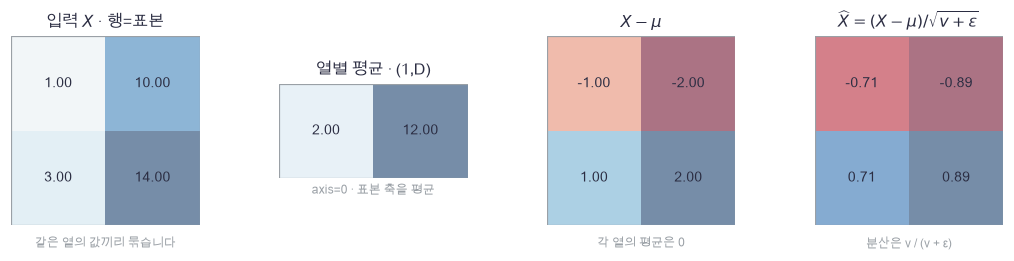

In [3]:
plot_axis_normalization(axis_x, axis_mean, axis_centered, axis_normalized)

🔍 **그림 확인**

평균을 뺀 뒤 각 열의 합은 0입니다. 마지막 열 값의 절댓값은 1보다 작습니다. ε를 분모에 더한 정확한 계산이므로 오류가 아닙니다. 이제 같은 열별 합을 반복문으로 한 번, NumPy의 축 연산으로 한 번 씁니다.

In [4]:
def normalize_columns_loops(x, epsilon):
    """열마다 평균·분산을 반복문으로 구해 (N,D) 배열을 정규화합니다."""
    assert epsilon > 0, "epsilon은 양수여야 합니다"
    n, d = x.shape
    result = np.zeros_like(x)
    for feature in range(d):
        mean = 0.0
        for sample in range(n):
            mean += x[sample, feature] / n
        variance = 0.0
        for sample in range(n):
            variance += (x[sample, feature] - mean) ** 2 / n
        for sample in range(n):
            result[sample, feature] = (x[sample, feature] - mean) / np.sqrt(variance + epsilon)
    return result

In [5]:
def centered_normalize(x, axis, epsilon=1e-5):
    """지정한 축의 평균을 빼고 크기를 조절하며 역전파용 통계를 반환합니다."""
    assert epsilon > 0, "epsilon은 양수여야 합니다"
    mean = np.mean(x, axis=axis, keepdims=True)
    centered = x - mean
    variance = np.mean(centered ** 2, axis=axis, keepdims=True)
    inverse = 1 / np.sqrt(variance + epsilon)
    normalized = centered * inverse
    return normalized, inverse, mean, variance

In [6]:
# 쓰는 것: axis_x, axis_mean, axis_var, axis_normalized (1절 그림 손계산)
loop_result = normalize_columns_loops(axis_x, epsilon=1.0)
vector_result, _, vector_mean, vector_var = centered_normalize(axis_x, axis=0, epsilon=1.0)
np.testing.assert_allclose(vector_mean, [[2., 12.]])  # 검산: 각 열의 평균은 2와 12입니다.
np.testing.assert_allclose(vector_var, [[1., 4.]])  # 검산: 분모 2로 계산한 분산은 1과 4입니다.
np.testing.assert_allclose(loop_result, vector_result)  # 검산: 반복문과 축 연산이 같습니다.
np.testing.assert_allclose(vector_result, axis_normalized)  # 검산: 구현은 그림의 직접 계산과 같습니다.
np.testing.assert_allclose(np.var(vector_result, axis=0), [0.5, 0.8])  # 검산: ε=1에서 분산은 1/2와 4/5입니다.
print("손계산 = 반복문 = 벡터화 · epsilon을 포함한 분산 확인")

손계산 = 반복문 = 벡터화 · epsilon을 포함한 분산 확인


### ✏️ 연습 1 · 분산의 분모와 축

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

`x`는 `(N,D)`입니다. 표본 축으로 평균 `mean`과 분모 N의 분산 `variance`를 두 줄로 구하세요.

In [7]:
def exercise_column_stats(x):
    """열마다 평균과 제곱 편차의 평균을 구합니다."""
    raise NotImplementedError
    return mean, variance

In [8]:
def check_column_stats(candidate):
    """두 열의 손계산 평균·분산을 독립적으로 검사합니다."""
    mean, variance = candidate(np.array([[0., 2.], [2., 6.]]))
    assert mean.shape == (1, 2), "평균한 표본 축을 길이 1로 남겨야 합니다"
    np.testing.assert_allclose(mean, [[1., 4.]])  # 검산: 열별 평균은 1과 4입니다.
    np.testing.assert_allclose(variance, [[1., 4.]])  # 검산: 두 표본으로 나눈 분산은 1과 4입니다.
run_check(check_column_stats, exercise_column_stats)

☐ exercise_column_stats: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean = np.mean(x, axis=0, keepdims=True)
variance = np.mean((x - mean) ** 2, axis=0, keepdims=True)
```

</details>

## 🔑 2. BatchNorm: 학습 통계와 평가 통계를 나누기

**이 절에서 가져갈 것:** BatchNorm의 입력·γ·β 기울기를 유도하고, 현재 배치로 계산하는 학습과 저장 통계로 계산하는 평가를 구분합니다.

같은 은닉 유닛을 여러 이미지가 얼마나 크게 켜는지 보고 크기를 맞춘다고 합시다. 현재 배치 안의 해당 유닛 값들이 통계를 결정합니다. 한 이미지의 값이 바뀌면 다른 이미지의 정규화 결과도 바뀔 수 있습니다.

> **용어** · **BatchNorm(BN, 배치 정규화)**는 여기서 특징마다 배치 표본들을 묶어 정규화합니다. **affine 변환**은 정규화 뒤의 학습 가능한 배율·이동 $Y=\gamma\odot\widehat X+\beta$입니다. γ·β는 특징마다 하나씩이고 표본 사이에 공유합니다.

학습에서는 1절의 열별 통계로

$$\mu_d=\frac1N\sum_nX_{nd},\quad v_d=\frac1N\sum_n(X_{nd}-\mu_d)^2,\quad Y_{nd}=\gamma_d\frac{X_{nd}-\mu_d}{\sqrt{v_d+\epsilon}}+\beta_d.$$

평가 때도 현재 배치로 통계를 내면 함께 평가하는 표본 구성에 따라 예측이 달라집니다. 여기서는 학습 중 평균·분산의 **지수이동평균(EMA)**을 따로 저장하고, 평가에서는 이를 고정합니다.

$$m\leftarrow(1-\alpha)m+\alpha\mu,\qquad s\leftarrow(1-\alpha)s+\alpha v,\quad \alpha=0.1.$$

**이 구현의 규약:** 초기값은 $m=0,s=1$입니다. $v$는 분모 $N$의 배치 분산이고, $N-1$로 보정하지 않습니다. 저장된 $s$는 이 분산들의 EMA이며 전체 학습 자료의 정확한 분산도, 불편 추정량도 아닙니다. 초기값 편향 보정은 하지 않습니다. 이 선택을 모든 프레임워크의 세부 구현과 같다고 간주하지 않습니다.

아래 그림은 같은 입력을 현재 통계와 별도로 정한 저장 통계로 계산한 차이입니다. γ=1, β=0입니다.

In [9]:
# 쓰는 것: axis_x (1절 손계산)
bn_picture_x = axis_x.copy()
bn_picture_mean = np.mean(bn_picture_x, axis=0, keepdims=True)
bn_picture_var = np.var(bn_picture_x, axis=0, keepdims=True)
bn_picture_train = (bn_picture_x - bn_picture_mean) / np.sqrt(bn_picture_var + 1e-5)
bn_saved_mean = np.array([[1., 8.]])
bn_saved_var = np.array([[4., 9.]])
bn_picture_eval = (bn_picture_x - bn_saved_mean) / np.sqrt(bn_saved_var + 1e-5)
bn_picture_stats = np.concatenate([bn_saved_mean, bn_saved_var], axis=0)

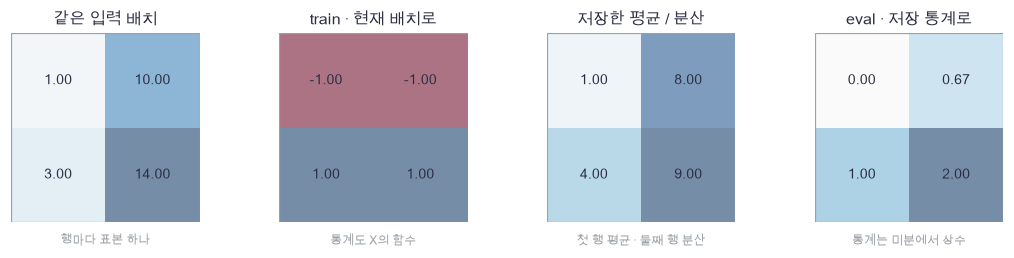

In [10]:
plot_bn_modes(bn_picture_x, bn_picture_train, bn_picture_stats, bn_picture_eval)

🔍 **그림 확인과 역전파**

train 출력은 각 열 평균이 0이지만 eval 출력은 그럴 필요가 없습니다. eval은 **지금 배치를 중심화하는 함수가 아니라 학습 때 저장한 기준으로 바꾸는 함수**이기 때문입니다. γ·β까지 학습하면 train의 최종 $Y$도 평균 0·분산 1일 필요가 없습니다.

출력 기울기 $G=dY$에서 먼저

$$d\gamma_d=\sum_n G_{nd}\widehat X_{nd},\quad d\beta_d=\sum_nG_{nd},\quad g_{nd}=G_{nd}\gamma_d.$$

한 열에서 $c_i=x_i-\mu$, $r=(v+\epsilon)^{-1/2}$라 두면 연쇄법칙은

$$dv=-\tfrac12r^3\sum_i g_ic_i,\quad d\mu=-r\sum_i g_i-\frac{2dv}{N}\sum_i c_i,\quad dx_i=g_ir+\frac{2c_i}{N}dv+\frac{d\mu}{N}.$$

$\sum_i c_i=0$을 사용해 정리하면 다음처럼 짧게 쓸 수 있습니다. ε를 버리지 않고도 정확한 식입니다.

$$dX=r\odot\left[g-\operatorname{mean}_0(g)-\widehat X\odot\operatorname{mean}_0(g\odot\widehat X)\right].$$

평가에서는 저장 통계를 상수로 두므로 $dX=G\odot\gamma/\sqrt{s+\epsilon}$만 남습니다. $d\gamma,d\beta$ 식은 같지만 그때의 $\widehat X$는 저장 통계로 계산한 값입니다. 통계 갱신을 forward 밖으로 분리해 중심차분 중에는 상태가 바뀌지 않게 합니다.

In [11]:
# 쓰는 것: centered_normalize (1절)
def bn_train_forward(x, gamma, beta, epsilon=1e-5):
    """현재 배치의 열별 통계로 BN을 계산하며 저장 통계는 바꾸지 않습니다."""
    normalized, inverse, mean, variance = centered_normalize(x, axis=0, epsilon=epsilon)
    y = normalized * gamma + beta
    cache = (normalized, inverse, gamma, mean, variance)
    return y, cache

In [12]:
def bn_train_backward(dy, cache):
    """배치 평균·분산 경로를 포함해 입력과 γ·β의 기울기를 계산합니다."""
    normalized, inverse, gamma, _, _ = cache
    dgamma = np.sum(dy * normalized, axis=0)
    dbeta = np.sum(dy, axis=0)
    g = dy * gamma
    dx = inverse * (g - np.mean(g, axis=0, keepdims=True)
                    - normalized * np.mean(g * normalized, axis=0, keepdims=True))
    return dx, dgamma, dbeta

In [13]:
def update_bn_statistics(state, cache, alpha=0.1):
    """분모 N의 배치 평균·분산을 학습 때만 별도 EMA 상태에 반영합니다."""
    _, _, _, mean, variance = cache
    state["mean"] = (1 - alpha) * state["mean"] + alpha * mean
    state["variance"] = (1 - alpha) * state["variance"] + alpha * variance

In [14]:
def bn_eval_forward(x, gamma, beta, state, epsilon=1e-5):
    """저장한 통계를 상수로 사용하고 상태를 갱신하지 않습니다."""
    assert epsilon > 0, "epsilon은 양수여야 합니다"
    inverse = 1 / np.sqrt(state["variance"] + epsilon)
    normalized = (x - state["mean"]) * inverse
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [15]:
def bn_eval_backward(dy, cache):
    """평가 통계를 상수로 고정한 입력·γ·β 기울기를 계산합니다."""
    normalized, inverse, gamma = cache
    dx = dy * gamma * inverse
    dgamma = np.sum(dy * normalized, axis=0)
    dbeta = np.sum(dy, axis=0)
    return dx, dgamma, dbeta

In [16]:
# 쓰는 것: bn_train_forward (2절), bn_picture_x, bn_picture_train, bn_picture_eval, bn_saved_mean, bn_saved_var (2절 그림)
bn_test_state = {"mean": bn_saved_mean.copy(), "variance": bn_saved_var.copy()}
bn_y, bn_cache = bn_train_forward(bn_picture_x, np.ones(2), np.zeros(2))
bn_eval_y, _ = bn_eval_forward(bn_picture_x, np.ones(2), np.zeros(2), bn_test_state)
np.testing.assert_allclose(bn_y, bn_picture_train)  # 검산: train 구현과 그림의 배치 통계 계산이 같습니다.
np.testing.assert_allclose(bn_eval_y, bn_picture_eval)  # 검산: eval 구현과 고정 통계 계산이 같습니다.
update_bn_statistics(bn_test_state, bn_cache, alpha=0.1)
np.testing.assert_allclose(bn_test_state["mean"], [[1.1, 8.4]])  # 검산: 평균은 0.9·(1,8)+0.1·(2,12)입니다.
np.testing.assert_allclose(bn_test_state["variance"], [[3.7, 8.5]])  # 검산: 분산은 0.9·(4,9)+0.1·(1,4)입니다.
print("BN train/eval forward와 별도 통계 갱신 검산 통과")

BN train/eval forward와 별도 통계 갱신 검산 통과


📎 **모든 원소의 중심차분 검사**

$L=\sum G\odot Y$라는 스칼라를 만들고 $X,\gamma,\beta$의 모든 원소를 하나씩 흔듭니다. $G$는 임의의 고정 배열입니다. 이 검사는 출력 일부나 특정한 손실 하나에서 우연히 맞는 오류를 줄여 줍니다. BN train 검사에는 저장 통계가 없고, eval 검사에는 고정한 통계만 전달합니다.

> **코드** · `zip(이름들, 배열들, 기울기들)`은 같은 위치의 항목을 하나씩 묶습니다. `.copy()`는 별도 배열을 만듭니다. 함수 안의 `objective`는 바깥 배열을 바라보므로 수치미분 도구가 그 배열을 흔들 때 바뀐 손실을 계산합니다. `_`는 돌려받은 값 중 지금 쓰지 않는 자리입니다.

In [17]:
def check_norm_gradients(forward, backward, x, gamma, beta=None):
    """고정 상류 기울기에서 입력·모든 affine 파라미터를 중심차분합니다."""
    upstream = np.random.default_rng(160).normal(size=x.shape)
    def objective():
        """현재 배열에서 출력과 고정 상류 기울기의 내적을 계산합니다."""
        if beta is None:
            y, _ = forward(x, gamma)
        else:
            y, _ = forward(x, gamma, beta)
        return float(np.sum(y * upstream))
    if beta is None:
        _, cache = forward(x, gamma)
        names, arrays = ["X", "gamma"], [x, gamma]
    else:
        _, cache = forward(x, gamma, beta)
        names, arrays = ["X", "gamma", "beta"], [x, gamma, beta]
    analytic = backward(upstream, cache)
    assert len(analytic) == len(arrays), "모든 입력·학습 파라미터의 기울기가 있어야 합니다"
    errors = {}
    for name, array, gradient in zip(names, arrays, analytic):
        numeric = numerical_gradient(objective, array)
        np.testing.assert_allclose(gradient, numeric, rtol=5e-5, atol=2e-8)  # 검산: 해당 배열의 모든 원소 기울기가 중심차분과 같습니다.
        errors[name] = rel_error(gradient, numeric)
    return errors

In [18]:
# 쓰는 것: bn_train_forward, bn_train_backward (2절)
check_rng = np.random.default_rng(161)
check_x = check_rng.normal(size=(3, 4))
check_gamma = np.array([1.2, -0.7, 0.5, 1.8])
check_beta = np.array([0.1, -0.2, 0.3, -0.4])
bn_train_errors = check_norm_gradients(bn_train_forward, bn_train_backward, check_x, check_gamma, check_beta)
print("BN train 전체 기울기:", bn_train_errors)

BN train 전체 기울기: {'X': 8.773345290119498e-10, 'gamma': 1.3159605865515073e-10, 'beta': 3.6395159405608015e-10}


In [19]:
# 쓰는 것: bn_eval_forward (2절)
fixed_eval_state = {"mean": np.array([[0.2, 0.1, -0.3, 0.5]]), "variance": np.array([[0.5, 2., 1., 0.8]])}

In [20]:
# 쓰는 것: bn_eval_forward, fixed_eval_state (2절)
def fixed_bn_eval(x, gamma, beta):
    """검사 중 바뀌지 않는 저장 통계로 평가 forward를 호출합니다."""
    return bn_eval_forward(x, gamma, beta, fixed_eval_state)

In [21]:
# 쓰는 것: check_norm_gradients, check_x, check_gamma, check_beta, bn_eval_backward, fixed_eval_state (2절)
saved_eval_mean = fixed_eval_state["mean"].copy()
saved_eval_variance = fixed_eval_state["variance"].copy()
bn_eval_errors = check_norm_gradients(fixed_bn_eval, bn_eval_backward, check_x, check_gamma, check_beta)
np.testing.assert_array_equal(fixed_eval_state["mean"], saved_eval_mean)  # 검산: 중심차분 중 저장 평균이 변하지 않습니다.
np.testing.assert_array_equal(fixed_eval_state["variance"], saved_eval_variance)  # 검산: 중심차분 중 저장 분산이 변하지 않습니다.
print("BN eval 전체 기울기:", bn_eval_errors)

BN eval 전체 기울기: {'X': 2.940984235351819e-10, 'gamma': 2.182450483586779e-10, 'beta': 4.574823840699579e-10}


### ✏️ 연습 2 · 평가 때의 입력 기울기

`dy`, `gamma`, 저장한 `variance`, `epsilon`을 받습니다. 평가 통계는 상수입니다. 입력 기울기 한 줄을 채우세요.

In [22]:
def exercise_bn_eval_dx(dy, gamma, variance, epsilon):
    """고정 통계인 BN eval의 입력 기울기를 구합니다."""
    raise NotImplementedError
    return dx

In [23]:
def check_bn_eval_dx(candidate):
    """분모가 2와 3인 독립적인 손계산으로 검사합니다."""
    result = candidate(np.array([[2., -3.]]), np.array([3., 2.]), np.array([[3., 8.]]), 1.)
    np.testing.assert_allclose(result, [[3., -2.]])  # 검산: 2·3/2=3, -3·2/3=-2입니다.
run_check(check_bn_eval_dx, exercise_bn_eval_dx)

☐ exercise_bn_eval_dx: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dx = dy * gamma / np.sqrt(variance + epsilon)
```

</details>

## 🔑 3. LayerNorm: 한 표본 안에서 기준을 만들기

**이 절에서 가져갈 것:** 특징 축의 정규화와 역전파를 구현하고, 다른 표본을 바꾸어도 같은 표본의 출력은 같음을 검산합니다.

숫자 7 한 장의 은닉 특징이 $(1,2,4)$라고 합시다. 함께 처리하는 이미지가 바뀌어도 이 세 값 안에서만 기준을 잡고 싶다면 표본 축 대신 **특징 축**을 묶습니다.

> **용어** · **LayerNorm(LN, 층 정규화)**는 한 표본의 지정한 특징 축에서 평균·분산을 계산합니다. 이 노트북의 `(N,D)` 입력에서는 `axis=1`입니다. 학습 때와 평가 때 같은 규칙을 쓰며 running 통계가 없습니다.

$$\mu_n=\frac1D\sum_dX_{nd},\quad v_n=\frac1D\sum_d(X_{nd}-\mu_n)^2,\quad Y_{nd}=\gamma_d\widehat X_{nd}+\beta_d.$$

$\mu,v$는 $(N,1)$이고, γ·β는 여전히 $(D,)$입니다. 통계의 묶음과 학습 파라미터를 공유하는 축을 구별해야 합니다. BN과 수식 모양은 같지만 평균의 축이 달라집니다.

한 표본의 특징들에 대해 $g=G\odot\gamma$라 놓으면

$$dX=r\odot\left[g-\operatorname{mean}_1(g)-\widehat X\odot\operatorname{mean}_1(g\odot\widehat X)\right].$$

γ가 특징마다 다르므로 **γ를 먼저 곱한 $g$를 평균**해야 합니다. γ를 괄호 바깥으로 꺼내고 $G$만 평균하면 일반적으로 다른 값이 됩니다. $d\gamma=\sum_nG\odot\widehat X$, $d\beta=\sum_nG$는 배치 축의 합입니다.

아래 두 배치의 첫 행은 같고 동료인 둘째 행만 다릅니다. LN은 첫 행의 결과를 유지하고 BN train은 달라집니다.

In [24]:
# 쓰는 것: centered_normalize (1절)
peers_a = np.array([[1., 2., 4.], [2., 3., 5.]])
peers_b = np.array([[1., 2., 4.], [9., -2., 0.]])
ln_a, _, _, _ = centered_normalize(peers_a, axis=1)
ln_b, _, _, _ = centered_normalize(peers_b, axis=1)
bn_a, _, _, _ = centered_normalize(peers_a, axis=0)
bn_b, _, _, _ = centered_normalize(peers_b, axis=0)
ln_target_rows = np.stack([ln_a[0], ln_b[0]])
bn_target_rows = np.stack([bn_a[0], bn_b[0]])

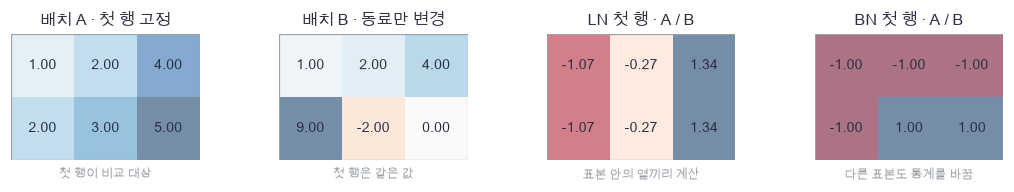

In [25]:
plot_batch_independence(peers_a, peers_b, ln_target_rows, bn_target_rows)

🔍 **그림 확인**

LN의 두 행은 같고 BN의 두 행은 다릅니다. 이는 어느 방식이 언제나 더 좋다는 뜻이 아니라 **서로 다른 함수를 계산한다**는 뜻입니다. LN은 이 입력에서 다른 표본을 미분 경로에 넣지 않습니다.

> **코드** · `np.stack([a, b])`는 같은 shape의 두 배열을 새 축에 쌓습니다. 이 그림에서는 같은 첫 표본의 결과 두 개를 비교하려고 `(2,D)` 배열을 만들었습니다.

이미지나 문장의 텐서에서는 정규화할 축을 다시 확인해야 합니다.

| 입력 shape | 여기서 연결할 정규화 | 통계에 포함하는 축 |
|---|---|---|
| MLP $(N,D)$ | BN | `axis=0`: 같은 특징의 여러 표본 |
| MLP $(N,D)$ | LN·RMS | `axis=1`: 한 표본의 특징 |
| CNN $(N,C,H,W)$ | 채널별 BN | `axis=(0,2,3)`: 같은 채널의 표본·공간 위치 |
| 토큰 $(N,T,D)$ | 마지막 특징 축 LN·RMS | `axis=-1`: 각 표본·토큰 안의 D개 특징 |

LN은 “항상 배치를 제외한 모든 축”이라는 고정 규칙이 아닙니다. **정규화하도록 지정한 특징 축**이 무엇인지 봐야 합니다. 이 노트북의 구현 범위는 읽기 쉬운 2차원 배열입니다.

In [26]:
# 쓰는 것: centered_normalize (1절)
def ln_forward(x, gamma, beta, epsilon=1e-5):
    """각 행의 특징을 정규화하며 γ·β는 특징별로 모든 표본에 공유합니다."""
    normalized, inverse, _, _ = centered_normalize(x, axis=1, epsilon=epsilon)
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [27]:
def ln_backward(dy, cache):
    """각 행의 평균·분산 경로를 포함해 LN 입력·γ·β를 미분합니다."""
    normalized, inverse, gamma = cache
    g = dy * gamma
    dx = inverse * (g - np.mean(g, axis=1, keepdims=True)
                    - normalized * np.mean(g * normalized, axis=1, keepdims=True))
    dgamma = np.sum(dy * normalized, axis=0)
    dbeta = np.sum(dy, axis=0)
    return dx, dgamma, dbeta

In [28]:
# 쓰는 것: peers_a, peers_b, ln_a, ln_b (3절 그림), check_norm_gradients, check_x, check_gamma, check_beta (2절)
actual_ln_a, _ = ln_forward(peers_a, np.ones(3), np.zeros(3))
actual_ln_b, _ = ln_forward(peers_b, np.ones(3), np.zeros(3))
np.testing.assert_allclose(actual_ln_a, ln_a)  # 검산: LN 구현은 그림의 직접 축 계산과 같습니다.
np.testing.assert_array_equal(actual_ln_a[0], actual_ln_b[0])  # 검산: 같은 첫 표본은 동료가 달라도 같은 결과입니다.
ln_errors = check_norm_gradients(ln_forward, ln_backward, check_x, check_gamma, check_beta)
print("LN 전체 기울기:", ln_errors)

LN 전체 기울기: {'X': 2.3238320683102303e-10, 'gamma': 3.675337198521751e-10, 'beta': 1.6816583112141673e-10}


In [29]:
# 쓰는 것: ln_forward, ln_backward (3절), peers_a (3절 그림)
_, peer_cache = ln_forward(peers_a, np.ones(3), np.zeros(3))
only_first_upstream = np.array([[0.2, -0.7, 1.1], [0., 0., 0.]])
peer_dx, _, _ = ln_backward(only_first_upstream, peer_cache)
np.testing.assert_array_equal(peer_dx[1], np.zeros(3))  # 검산: 첫 표본 손실에서 동료 표본으로 미분 경로가 없습니다.
print("LN 표본 사이 미분 경로 분리 검산 통과")

LN 표본 사이 미분 경로 분리 검산 통과


### ✏️ 연습 3 · 한 표본씩 중심화하기

`x`가 `(N,D)`일 때 각 행의 평균을 빼는 한 줄을 채우세요. 같은 행에 더해진 상수는 없어져야 합니다.

In [30]:
def exercise_center_rows(x):
    """표본별 특징 평균을 빼고 원래 shape를 유지합니다."""
    raise NotImplementedError
    return centered

In [31]:
def check_center_rows(candidate):
    """평균이 다른 두 표본의 중심화 결과를 검사합니다."""
    result = candidate(np.array([[1., 3.], [10., 14.]]))
    np.testing.assert_allclose(result, [[-1., 1.], [-2., 2.]])  # 검산: 행별 평균 2와 12를 뺍니다.
run_check(check_center_rows, exercise_center_rows)

☐ exercise_center_rows: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
centered = x - np.mean(x, axis=1, keepdims=True)
```

</details>

## 🔑 4. RMSNorm: 중심은 남기고 크기만 조절하기

**이 절에서 가져갈 것:** RMSNorm의 역전파를 구현하고, 이동·배율·상수 입력·작은 묶음에서 세 방식의 차이를 검산합니다.

한 표본의 특징이 모두 양수인 $(2,2,2)$라면 LN은 평균을 빼서 모두 0으로 만듭니다. 양수 방향의 공통 크기 정보를 남긴 채 크기만 조절하려면 평균을 빼지 않는 연산을 생각할 수 있습니다.

> **용어** · **RMS(root mean square)**는 제곱 평균의 제곱근입니다. **RMSNorm**은 특징의 RMS로 크기를 조절하는 정규화입니다. 여기서는 특징별 γ를 학습하고 β는 두지 않습니다.

$$q_n=\frac1D\sum_dX_{nd}^2,\quad r_n=(q_n+\epsilon)^{-1/2},\quad \widehat X_{nd}=X_{nd}r_n,\quad Y_{nd}=\gamma_d\widehat X_{nd}.$$

평균을 빼지 않으므로 일반적으로 $\operatorname{mean}_1(\widehat X)\ne0$입니다. 제곱 평균은 $q/(q+\epsilon)$이고 ε가 0이 아니면 정확히 1이라고 할 수 없습니다.

$g=G\odot\gamma$에서 $dr=\sum_dg_dX_d$, $dq=-\tfrac12r^3dr$, $dX=g r+2X dq/D$를 정리하면

$$dX=r\odot\left[g-\widehat X\odot\operatorname{mean}_1(g\odot\widehat X)\right],\qquad d\gamma=\sum_nG\odot\widehat X.$$

LN의 식과 비교하면 평균 제거에서 온 $-\operatorname{mean}_1(g)$ 항이 없습니다. 다음은 같은 입력에 γ=1, β=0 조건을 적용한 그림입니다.

In [32]:
# 쓰는 것: centered_normalize (1절)
compare_x = np.array([[2., 2., 2.], [1., 2., 4.], [-2., -1., 1.]])
compare_bn, _, _, _ = centered_normalize(compare_x, axis=0)
compare_ln, _, _, _ = centered_normalize(compare_x, axis=1)
compare_rms = compare_x / np.sqrt(np.mean(compare_x ** 2, axis=1, keepdims=True) + 1e-5)

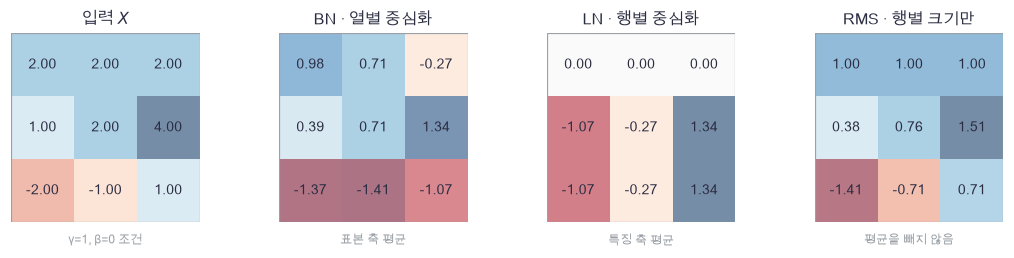

In [33]:
plot_norm_comparison(compare_x, compare_bn, compare_ln, compare_rms)

🔍 **그림 확인**

첫 행이 상수일 때 LN은 0, RMS는 약 1을 냅니다. BN은 열의 다른 표본들과 비교하므로 첫 행이 상수라는 사실만으로 0이 되지 않습니다. 정규화 축과 평균 제거 유무가 각각 별도의 선택임을 볼 수 있습니다.

아래는 affine 변환 전의 성질입니다. 중심화하는 BN·LN은 **정규화 묶음 전체에 같은 상수**를 더해도 그대로입니다. RMS는 이동 불변이 아닙니다. 반면 양수 $a$로 묶음 전체를 곱하면 세 방식 모두

$$\operatorname{norm}(aX;\epsilon)=\operatorname{norm}(X;\epsilon/a^2).$$

따라서 고정 ε에서는 정확한 배율 불변이 아니라, 원래 분산 또는 제곱 평균이 ε보다 충분히 클 때 근사적으로 같습니다. BN eval은 저장 통계가 고정되어 있으므로 현재 입력만 바꾸는 이런 train 성질을 그대로 적용하면 안 됩니다.

In [34]:
def rms_forward(x, gamma, epsilon=1e-5):
    """표본별 제곱 평균으로 크기만 조절하며 특징별 γ를 곱합니다."""
    assert epsilon > 0, "epsilon은 양수여야 합니다"
    inverse = 1 / np.sqrt(np.mean(x ** 2, axis=1, keepdims=True) + epsilon)
    normalized = x * inverse
    return normalized * gamma, (normalized, inverse, gamma)

In [35]:
def rms_backward(dy, cache):
    """평균 제거 항이 없는 RMSNorm의 입력·γ 기울기를 계산합니다."""
    normalized, inverse, gamma = cache
    g = dy * gamma
    dx = inverse * (g - normalized * np.mean(g * normalized, axis=1, keepdims=True))
    dgamma = np.sum(dy * normalized, axis=0)
    return dx, dgamma

In [36]:
# 쓰는 것: compare_x, compare_rms (4절 그림), check_norm_gradients, check_x, check_gamma (2절)
rms_actual, _ = rms_forward(compare_x, np.ones(3))
np.testing.assert_allclose(rms_actual, compare_rms)  # 검산: RMS 구현은 그림의 직접 계산과 같습니다.
rms_errors = check_norm_gradients(rms_forward, rms_backward, check_x, check_gamma)
print("RMS 전체 기울기:", rms_errors)

RMS 전체 기울기: {'X': 1.8112355994149636e-10, 'gamma': 3.074432902473613e-10}


In [37]:
# 쓰는 것: centered_normalize (1절), check_x (2절), rms_forward (4절)
shift = np.array([[2.], [-1.], [4.]])
ln_original, _, _, _ = centered_normalize(check_x, axis=1)
ln_shifted, _, _, _ = centered_normalize(check_x + shift, axis=1)
rms_original, _ = rms_forward(check_x, np.ones(4))
rms_shifted, _ = rms_forward(check_x + shift, np.ones(4))
np.testing.assert_allclose(ln_shifted, ln_original, atol=1e-14)  # 검산: LN은 행 전체에 더한 같은 상수를 제거합니다.
assert not np.allclose(rms_shifted, rms_original), "RMS는 이 입력의 상수 이동을 제거하지 않습니다"
scaled_ln, _, _, _ = centered_normalize(3 * check_x, axis=1, epsilon=0.1)
matched_ln, _, _, _ = centered_normalize(check_x, axis=1, epsilon=0.1 / 9)
np.testing.assert_allclose(scaled_ln, matched_ln, atol=1e-14)  # 검산: 세 배 입력은 epsilon을 아홉 배 줄인 결과와 같습니다.
fixed_epsilon_ln, _, _, _ = centered_normalize(check_x, axis=1, epsilon=0.1)
assert not np.allclose(scaled_ln, fixed_epsilon_ln), "유한 epsilon에서 배율 불변을 정확한 등식으로 쓰면 안 됩니다"
print("이동과 epsilon을 포함한 정확한 배율 관계 검산 통과")

이동과 epsilon을 포함한 정확한 배율 관계 검산 통과


In [38]:
# 쓰는 것: ln_forward, ln_backward (3절), rms_forward, rms_backward (4절), check_norm_gradients (2절)
constant_x = np.full((2, 3), 2.0)
constant_ln, _ = ln_forward(constant_x, np.ones(3), np.zeros(3))
constant_rms, _ = rms_forward(constant_x, np.ones(3))
np.testing.assert_array_equal(constant_ln, np.zeros_like(constant_x))  # 검산: LN의 상수 행은 0입니다.
np.testing.assert_allclose(constant_rms, 2 / np.sqrt(4 + 1e-5))  # 검산: RMS는 상수 행의 양수 방향을 남깁니다.
constant_errors = check_norm_gradients(ln_forward, ln_backward, constant_x, np.ones(3), np.zeros(3))
zero_rms_errors = check_norm_gradients(rms_forward, rms_backward, np.zeros((2, 3)), np.ones(3))
print("상수 LN·영 입력 RMS의 전체 기울기 검산 통과")

상수 LN·영 입력 RMS의 전체 기울기 검산 통과


In [39]:
# 쓰는 것: centered_normalize (1절), check_x, check_norm_gradients, bn_train_forward, bn_train_backward (2절), rms_forward, rms_backward (4절)
bn_original, _, _, _ = centered_normalize(check_x, axis=0)
bn_shifted, _, _, _ = centered_normalize(check_x + np.array([[2., -1., 4., 3.]]), axis=0)
np.testing.assert_allclose(bn_shifted, bn_original, atol=1e-14)  # 검산: BN train은 열 전체에 더한 같은 상수를 제거합니다.
rms_scaled, _ = rms_forward(3 * check_x, np.ones(4), epsilon=0.1)
rms_epsilon_matched, _ = rms_forward(check_x, np.ones(4), epsilon=0.1 / 9)
np.testing.assert_allclose(rms_scaled, rms_epsilon_matched, atol=1e-14)  # 검산: RMS에도 세 배 입력과 epsilon 1/9의 정확한 관계가 성립합니다.
constant_bn_errors = check_norm_gradients(bn_train_forward, bn_train_backward, np.ones((3, 2)), np.ones(2), np.zeros(2))
print("BN의 이동·상수 입력 기울기와 RMS의 배율 관계 검산 통과")

BN의 이동·상수 입력 기울기와 RMS의 배율 관계 검산 통과


📎 **BN에서 묶음이 하나뿐이면**

이 2차원 BN의 배치 크기 $N=1$에서는 평균이 그 표본 자체이고 분산은 0입니다. train 출력은 β, 입력·γ 기울기는 0이 되어 입력 차이를 학습으로 전달하지 못합니다. ε를 작게 바꿔도 이 사실은 바뀌지 않습니다. 이 교육용 구현은 계산을 허용해 결과를 보여 줍니다. 일부 라이브러리가 이 조건을 허용하는지와는 별개의 규약입니다.

CNN BN의 묶음 크기는 보통 $NHW$이므로 이미지 수가 1이어도 공간 위치가 여러 개면 같은 조건이 아닙니다. LN도 특징 수 $D=1$로 중심화하면 비슷하게 정보가 사라집니다. **배치 크기와 정규화 묶음의 원소 수를 구분**해야 합니다.

In [40]:
# 쓰는 것: bn_train_forward, bn_train_backward, bn_eval_forward, check_norm_gradients (2절)
single_x = np.array([[1., -2., 3.]])
single_gamma = np.array([0.5, 2., -1.])
single_beta = np.array([0.1, 0.2, 0.3])
single_y, single_cache = bn_train_forward(single_x, single_gamma, single_beta)
single_dx, single_dgamma, single_dbeta = bn_train_backward(np.ones_like(single_x), single_cache)
np.testing.assert_allclose(single_y, single_beta[None, :])  # 검산: BN train 배치 1의 출력은 β뿐입니다.
np.testing.assert_array_equal(single_dx, np.zeros_like(single_x))  # 검산: 평균 경로가 직접 입력 경로를 상쇄합니다.
np.testing.assert_array_equal(single_dgamma, np.zeros(3))  # 검산: 정규화 값이 0이라 γ 기울기도 0입니다.
single_errors = check_norm_gradients(bn_train_forward, bn_train_backward, single_x, single_gamma, single_beta)
print("BN 배치 1의 forward·모든 기울기 경계 검산 통과")

BN 배치 1의 forward·모든 기울기 경계 검산 통과


### ✏️ 연습 4 · RMS와 중심화의 차이

`x`와 양수 `epsilon`을 받아 γ=1인 RMS 결과를 한 줄로 채우세요. 평균을 빼지 않습니다.

In [41]:
def exercise_rms_values(x, epsilon):
    """각 행의 제곱 평균으로만 크기를 조절합니다."""
    raise NotImplementedError
    return normalized

In [42]:
def check_rms_values(candidate):
    """상수 행에서도 평균을 제거하지 않는지 손계산으로 검사합니다."""
    result = candidate(np.array([[2., 2.]]), 5.)
    np.testing.assert_allclose(result, [[2 / 3, 2 / 3]])  # 검산: 분모는 sqrt(4+5)=3입니다.
run_check(check_rms_values, exercise_rms_values)

☐ exercise_rms_values: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
normalized = x / np.sqrt(np.mean(x ** 2, axis=1, keepdims=True) + epsilon)
```

</details>

## 🔑 5. 같은 MNIST 분류기에 네 방식을 넣어 보기

**이 절에서 가져갈 것:** 같은 초기 가중치·배치 순서·학습 설정에서 정규화만 바꾸고, 고정한 평가 규칙으로 결과를 비교합니다.

정규화 식이 맞다는 사실과 특정 문제의 성능이 좋아진다는 주장은 다릅니다. 이번에는 숫자 그림을 10개 점수로 바꾸는 작은 MLP에 정규화 층을 넣고 실제 학습을 해 봅니다.

> **용어** · **MLP**는 선형 층과 원소별 비선형 함수를 연결한 신경망입니다. **logit**은 softmax에 넣기 전의 클래스 점수입니다. **교차엔트로피(CE)**는 정답 클래스에 준 확률의 음의 로그입니다. **독립 평가**에서는 학습 때 보지 않은 표본과 고정한 모델을 사용합니다.

$$U=XW_1+b_1\in\mathbb R^{N\times48},\quad V=\operatorname{Norm}(U),\quad H=\tanh(V),\quad S=HW_2+b_2\in\mathbb R^{N\times10}.$$

정규화를 쓰지 않으면 $V=U$입니다. BN·LN은 γ와 β를, RMS는 γ만 학습합니다. γ는 1, β는 0에서 시작합니다. 앞뒤 가중치와 편향, 입력과 배치 순서는 네 방식에서 같습니다. 추가 파라미터 수는 실제 배열에서 세어 출력합니다.

손실은 표본 수 $N$으로 평균하고,

$$p_{nk}=\frac{e^{S_{nk}}}{\sum_j e^{S_{nj}}},\quad J=-\frac1N\sum_n\log p_{n,y_n},\quad dS=(p-\operatorname{onehot}(y))/N.$$

계산은 안정적인 log-softmax로 하여 큰 logit 차이에서도 손실이 잘리지 않게 합니다. 아래는 학습 전 고정 숫자 7을 **LN 경로**에 넣은 그림입니다. 그림용 통계와 모든 중간 배열은 본문에서 계산합니다.

In [43]:
# 고정 예시와 학습 전 LN 경로의 직접 계산입니다.
example_images, example_labels = load_examples(download=True)
flow_rng = np.random.default_rng(165)
flow_w1 = flow_rng.normal(0, 1 / np.sqrt(784), (784, 48))
flow_w2 = flow_rng.normal(0, 1 / np.sqrt(48), (48, 10))
flow_x = example_images[7].reshape(1, 784)
flow_u = flow_x @ flow_w1
flow_v = (flow_u - np.mean(flow_u, axis=1, keepdims=True)) / np.sqrt(np.var(flow_u, axis=1, keepdims=True) + 1e-5)
flow_h = np.tanh(flow_v)
flow_scores = flow_h @ flow_w2

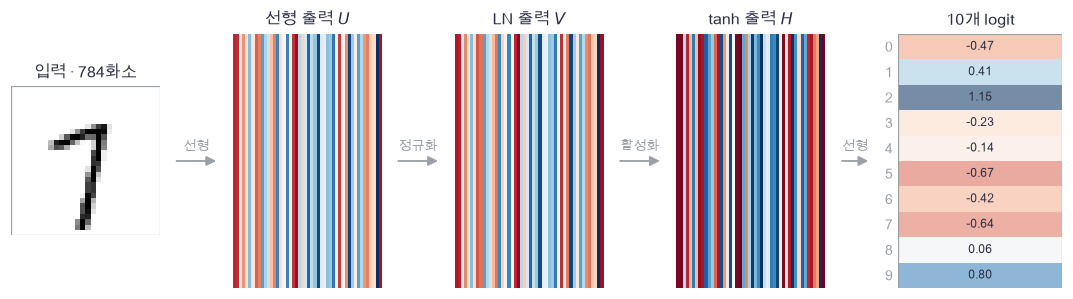

In [44]:
plot_mlp_norm_flow(example_images[7], flow_u[0], flow_v[0], flow_h[0], flow_scores[0])

🔍 **그림 확인과 실험 설정**

정규화가 놓이는 자리는 첫 선형 층과 tanh 사이입니다. 은닉 값의 중심·크기를 바꿔도 마지막 점수가 곧바로 올바른 숫자를 가리키지는 않습니다. 분류 손실의 기울기로 전체 가중치와 정규화 파라미터를 함께 학습해야 합니다.

| 항목 | 고정 설정 |
|---|---|
| train | MNIST train 파일의 앞 2,000장 |
| validation | 같은 파일의 다음 400장, 가중치·running 통계 갱신에 쓰지 않음 |
| test | 별도 MNIST test 파일의 앞 600장 |
| 구조·학습 | 784→48→10, tanh, 배치 64, 5 epoch, 학습률 0.03 |
| optimizer | Momentum: $v\leftarrow0.9v+g$, $\theta\leftarrow\theta-0.03v$ |
| 선택 규칙 | 검증 결과로 설정·epoch를 다시 고르지 않고 마지막 모델을 평가 |

검증·평가의 BN은 저장 통계로 계산합니다. LN·RMS에는 train/eval에 따라 바뀌는 통계가 없습니다. 학습 곡선은 작은 고정 실험 하나이며 어떤 방식이 항상 낫다는 결론을 내리지 않습니다.

> **코드** · `np.arange(N)`은 0부터 N−1까지의 행 번호입니다. `log_probs[rows, labels]`는 각 행의 정답 클래스 칸을 고릅니다. 사전 `{이름: 배열}`로 파라미터와 optimizer 상태를 관리하며 `params.items()`로 이름·배열을 함께 꺼냅니다. `rng.permutation(N)`은 표본 순서를 섞습니다.

In [45]:
def softmax_cross_entropy(logits, labels):
    """안정적인 log-softmax로 평균 CE와 logit 기울기를 반환합니다."""
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    log_probs = shifted - np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))
    rows = np.arange(len(labels))
    loss = -np.mean(log_probs[rows, labels])
    gradient = np.exp(log_probs)
    gradient[rows, labels] -= 1
    gradient /= len(labels)
    return float(loss), gradient

In [46]:
def init_classifier(kind, input_dim=784, hidden_dim=48, classes=10, seed=165):
    """공통 가중치를 만들고 해당 방식에서 실제 학습하는 affine 변수만 더합니다."""
    rng = np.random.default_rng(seed)
    params = {
        "W1": rng.normal(0, 1 / np.sqrt(input_dim), (input_dim, hidden_dim)),
        "b1": np.zeros(hidden_dim),
        "W2": rng.normal(0, 1 / np.sqrt(hidden_dim), (hidden_dim, classes)),
        "b2": np.zeros(classes),
    }
    if kind in ("BN", "LN", "RMS"):
        params["gamma"] = np.ones(hidden_dim)
    if kind in ("BN", "LN"):
        params["beta"] = np.zeros(hidden_dim)
    state = None
    if kind == "BN":
        state = {"mean": np.zeros((1, hidden_dim)), "variance": np.ones((1, hidden_dim))}
    return params, state

In [47]:
# 쓰는 것: bn_train_forward, bn_eval_forward (2절), ln_forward (3절), rms_forward (4절)
def classifier_forward(x, params, kind, state, training):
    """선형 → 선택한 정규화 → tanh → 선형 순서로 점수를 계산합니다."""
    # 1) 첫 선형 층과 정규화 방식별 통계 경로를 선택합니다.
    u = x @ params["W1"] + params["b1"]
    norm_cache = None
    if kind == "BN":
        if training:
            v, norm_cache = bn_train_forward(u, params["gamma"], params["beta"])
        else:
            v, norm_cache = bn_eval_forward(u, params["gamma"], params["beta"], state)
    elif kind == "LN":
        v, norm_cache = ln_forward(u, params["gamma"], params["beta"])
    elif kind == "RMS":
        v, norm_cache = rms_forward(u, params["gamma"])
    elif kind == "none":
        v = u
    else:
        raise ValueError("kind는 none, BN, LN, RMS 중 하나여야 합니다")
    # 2) 활성화와 마지막 선형 층 뒤에 역전파용 배열을 남깁니다.
    h = np.tanh(v)
    logits = h @ params["W2"] + params["b2"]
    return logits, (x, h, norm_cache)

In [48]:
# 쓰는 것: bn_train_backward, bn_eval_backward (2절), ln_backward (3절), rms_backward (4절)
def classifier_backward(dlogits, cache, params, kind, training):
    """출력 기울기를 정규화 층까지 돌려 모든 파라미터와 입력을 미분합니다."""
    x, h, norm_cache = cache
    # 1) 마지막 선형 층과 tanh를 미분합니다.
    gradients = {"W2": h.T @ dlogits, "b2": np.sum(dlogits, axis=0)}
    dh = dlogits @ params["W2"].T
    dv = dh * (1 - h ** 2)
    # 2) forward에서 선택한 것과 같은 통계 경로를 거슬러 갑니다.
    if kind == "BN":
        if training:
            du, gradients["gamma"], gradients["beta"] = bn_train_backward(dv, norm_cache)
        else:
            du, gradients["gamma"], gradients["beta"] = bn_eval_backward(dv, norm_cache)
    elif kind == "LN":
        du, gradients["gamma"], gradients["beta"] = ln_backward(dv, norm_cache)
    elif kind == "RMS":
        du, gradients["gamma"] = rms_backward(dv, norm_cache)
    else:
        du = dv
    # 3) 첫 선형 층을 미분해 입력까지 돌아갑니다.
    gradients["W1"] = x.T @ du
    gradients["b1"] = np.sum(du, axis=0)
    dx = du @ params["W1"].T
    return dx, gradients

In [49]:
def momentum_update(params, gradients, velocity, learning_rate=0.03):
    """v=0.9v+g 규약으로 누적한 기울기를 빼고 파라미터를 갱신합니다."""
    for name in params:
        velocity[name] = 0.9 * velocity[name] + gradients[name]
        params[name] -= learning_rate * velocity[name]

In [50]:
# 쓰는 것: softmax_cross_entropy, init_classifier, classifier_forward, flow_x, flow_scores (5절)
extreme_loss, extreme_gradient = softmax_cross_entropy(np.array([[1000., -1000.], [-1000., 1000.]]), np.array([1, 0]))
np.testing.assert_allclose(extreme_loss, 2000.)  # 검산: 극단적인 오답 logit 차이를 손실에서 자르지 않습니다.
np.testing.assert_allclose(extreme_gradient, [[0.5, -0.5], [-0.5, 0.5]])  # 검산: 두 표본의 평균 CE 기울기입니다.
flow_params, flow_state = init_classifier("LN")
actual_flow_scores, _ = classifier_forward(flow_x, flow_params, "LN", flow_state, training=True)
np.testing.assert_allclose(actual_flow_scores, flow_scores, atol=1e-14)  # 검산: 전체 모델은 그림의 직접 계산과 같습니다.
print("안정적인 CE와 전체 forward 검산 통과")

안정적인 CE와 전체 forward 검산 통과


📎 **층을 연결한 뒤에도 검산합니다**

각 정규화의 미분이 맞아도 모델에서 다른 backward를 부르거나 배치 평균을 두 번 나누면 학습 기울기가 틀립니다. 작은 4→4→3 분류기를 만들어 각 방식의 **전체 파라미터와 입력**을 다시 검사합니다. BN의 학습·평가 경로는 따로 검사하고, 이때 EMA 갱신 함수는 호출하지 않습니다.

In [51]:
# 쓰는 것: init_classifier, classifier_forward, classifier_backward, softmax_cross_entropy (5절)
def check_classifier_gradients(kind, training=True):
    """작은 연결 모델의 모든 파라미터·입력을 실제 CE의 중심차분으로 검사합니다."""
    x = np.random.default_rng(167).normal(size=(3, 4))
    labels = np.array([0, 2, 1])
    params, state = init_classifier(kind, input_dim=4, hidden_dim=4, classes=3)
    logits, cache = classifier_forward(x, params, kind, state, training)
    _, dlogits = softmax_cross_entropy(logits, labels)
    dx, gradients = classifier_backward(dlogits, cache, params, kind, training)
    def objective():
        """고정 labels·통계로 현재 모델의 CE를 계산합니다."""
        scores, _ = classifier_forward(x, params, kind, state, training)
        loss, _ = softmax_cross_entropy(scores, labels)
        return loss
    errors = []
    for name, array in params.items():
        numeric = numerical_gradient(objective, array)
        np.testing.assert_allclose(gradients[name], numeric, rtol=5e-5, atol=2e-8)  # 검산: 연결한 모델에서도 모든 학습 파라미터의 기울기가 맞습니다.
        errors.append(np.max(np.abs(gradients[name] - numeric)))
    numeric_x = numerical_gradient(objective, x)
    np.testing.assert_allclose(dx, numeric_x, rtol=5e-5, atol=2e-8)  # 검산: 연결한 모델의 입력 기울기도 맞습니다.
    errors.append(np.max(np.abs(dx - numeric_x)))
    return float(max(errors))

In [52]:
for norm_kind in ["none", "BN", "LN", "RMS"]:
    error = check_classifier_gradients(norm_kind)
    print(f"{norm_kind:4s} 연결 모델 최대 절대오차: {error:.2e}")
print("BN eval 연결 모델 최대 절대오차:", check_classifier_gradients("BN", training=False))

none 연결 모델 최대 절대오차: 2.54e-10
BN   연결 모델 최대 절대오차: 2.86e-10
LN   연결 모델 최대 절대오차: 2.69e-10
RMS  연결 모델 최대 절대오차: 2.16e-10
BN eval 연결 모델 최대 절대오차: 1.974063135179449e-10


In [53]:
# 쓰는 것: momentum_update (5절)
step_params = {"w": np.array([1., -2.])}
step_velocity = {"w": np.zeros(2)}
momentum_update(step_params, {"w": np.array([2., -4.])}, step_velocity)
np.testing.assert_allclose(step_params["w"], [0.94, -1.88])  # 검산: 첫 갱신은 원래 값에서 0.03·기울기를 뺍니다.
momentum_update(step_params, {"w": np.zeros(2)}, step_velocity)
np.testing.assert_allclose(step_params["w"], [0.886, -1.772])  # 검산: 새 기울기가 0이어도 이전 속도의 0.9배가 남습니다.
print("Momentum의 두 단계 상태 갱신 검산 통과")

Momentum의 두 단계 상태 갱신 검산 통과


In [54]:
# 학습·검증·평가 분할은 학습 결과를 보기 전에 고정합니다.
mnist_all_train, mnist_all_labels, mnist_all_test, mnist_test_labels = load_mnist(download=True)
mnist_train_x = mnist_all_train[:2000].copy()
mnist_train_y = mnist_all_labels[:2000].copy()
mnist_valid_x = mnist_all_train[2000:2400].copy()
mnist_valid_y = mnist_all_labels[2000:2400].copy()
mnist_test_x = mnist_all_test[:600].copy()
mnist_test_y = mnist_test_labels[:600].copy()
del mnist_all_train, mnist_all_labels, mnist_all_test, mnist_test_labels
print("train / validation / test:", len(mnist_train_x), len(mnist_valid_x), len(mnist_test_x))

train / validation / test: 2000 400 600


In [55]:
# 쓰는 것: init_classifier, classifier_forward, classifier_backward, softmax_cross_entropy, momentum_update (5절), update_bn_statistics (2절)
def train_classifier(kind, x_train, y_train, x_valid, y_valid, epochs=5, batch_size=64):
    """같은 초기화·순서에서 학습하고 epoch 끝에 고정 통계로 검증합니다."""
    # 1) 방식별로 같은 seed에서 다시 시작하고 실제 학습 변수만 갱신합니다.
    params, state = init_classifier(kind)
    velocity = {name: np.zeros_like(array) for name, array in params.items()}
    order_rng = np.random.default_rng(166)
    history = []
    for epoch in range(1, epochs + 1):
        order = order_rng.permutation(len(x_train))
        weighted_loss = 0.0
        # 2) 배치 손실과 기울기를 계산합니다. BN 통계는 학습에서만 갱신합니다.
        for start in range(0, len(order), batch_size):
            indices = order[start:start + batch_size]
            logits, cache = classifier_forward(x_train[indices], params, kind, state, training=True)
            loss, dlogits = softmax_cross_entropy(logits, y_train[indices])
            _, gradients = classifier_backward(dlogits, cache, params, kind, training=True)
            if kind == "BN":
                update_bn_statistics(state, cache[2])
            momentum_update(params, gradients, velocity)
            weighted_loss += len(indices) * loss
        # 3) validation은 파라미터·running 통계를 바꾸지 않습니다.
        valid_logits, _ = classifier_forward(x_valid, params, kind, state, training=False)
        valid_loss, _ = softmax_cross_entropy(valid_logits, y_valid)
        valid_accuracy = np.mean(np.argmax(valid_logits, axis=1) == y_valid)
        train_loss = weighted_loss / len(x_train)
        assert np.isfinite(train_loss + valid_loss), "학습·검증 손실은 유한해야 합니다"
        history.append([epoch, train_loss, valid_loss, valid_accuracy])
        print(f"{kind:4s} epoch {epoch}: train CE={train_loss:.3f}, valid CE={valid_loss:.3f}, valid acc={valid_accuracy:.3f}")
    return params, state, np.asarray(history)

In [56]:
# 쓰는 것: mnist_train_x, mnist_train_y, mnist_valid_x, mnist_valid_y (5절 자료 분할)
training_started = perf_counter()
norm_names = ["none", "BN", "LN", "RMS"]
trained_models = {}
training_histories = []
for norm_kind in norm_names:
    params, state, history = train_classifier(norm_kind, mnist_train_x, mnist_train_y, mnist_valid_x, mnist_valid_y)
    trained_models[norm_kind] = (params, state)
    training_histories.append(history)
print(f"네 방식 학습 시간: {perf_counter() - training_started:.1f}초")

none epoch 1: train CE=1.351, valid CE=0.612, valid acc=0.820
none epoch 2: train CE=0.509, valid CE=0.397, valid acc=0.877
none epoch 3: train CE=0.371, valid CE=0.347, valid acc=0.897
none epoch 4: train CE=0.318, valid CE=0.354, valid acc=0.892
none epoch 5: train CE=0.277, valid CE=0.318, valid acc=0.905
BN   epoch 1: train CE=0.962, valid CE=0.464, valid acc=0.855
BN   epoch 2: train CE=0.421, valid CE=0.354, valid acc=0.897
BN   epoch 3: train CE=0.326, valid CE=0.337, valid acc=0.897


BN   epoch 4: train CE=0.279, valid CE=0.308, valid acc=0.910


BN   epoch 5: train CE=0.225, valid CE=0.296, valid acc=0.910


LN   epoch 1: train CE=1.112, valid CE=0.485, valid acc=0.863
LN   epoch 2: train CE=0.427, valid CE=0.356, valid acc=0.900
LN   epoch 3: train CE=0.313, valid CE=0.321, valid acc=0.915
LN   epoch 4: train CE=0.265, valid CE=0.336, valid acc=0.897
LN   epoch 5: train CE=0.225, valid CE=0.294, valid acc=0.907
RMS  epoch 1: train CE=1.106, valid CE=0.482, valid acc=0.860
RMS  epoch 2: train CE=0.425, valid CE=0.353, valid acc=0.902
RMS  epoch 3: train CE=0.310, valid CE=0.319, valid acc=0.915
RMS  epoch 4: train CE=0.262, valid CE=0.338, valid acc=0.892
RMS  epoch 5: train CE=0.222, valid CE=0.296, valid acc=0.907
네 방식 학습 시간: 0.1초


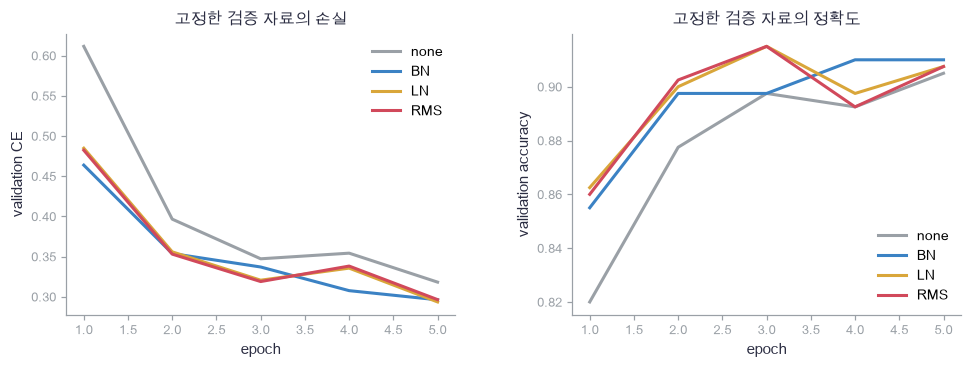

In [57]:
plot_norm_training(training_histories, norm_names)

🔍 **학습 기록 확인**

위 그림은 같은 validation 400장에서 측정한 CE와 정확도입니다. train CE는 배치를 갱신하기 직전 손실의 가중평균이고, validation은 epoch가 끝난 한 모델의 결과입니다. 특히 BN train은 배치 통계, BN validation은 저장 통계를 써서 두 값의 함수도 다릅니다. 이 차이를 무조건 과적합이나 오류로 해석하지 않습니다.

아래에서는 train·validation에 포함되지 않은 test 600장을 모두 평가합니다. 파라미터 수에는 실제 갱신하는 γ·β만 포함하고, BN의 running 평균·분산은 **학습 파라미터가 아닌 상태**로 따로 셉니다. 그림은 그중 앞 6장만 보여 주므로 전체 600장의 지표와 구별합니다.

In [58]:
# 쓰는 것: trained_models, norm_names, classifier_forward, softmax_cross_entropy, mnist_test_x, mnist_test_y (5절)
test_predictions = []
for norm_kind in norm_names:
    params, state = trained_models[norm_kind]
    logits, _ = classifier_forward(mnist_test_x, params, norm_kind, state, training=False)
    loss, _ = softmax_cross_entropy(logits, mnist_test_y)
    predictions = np.argmax(logits, axis=1)
    accuracy = np.mean(predictions == mnist_test_y)
    parameter_count = sum(array.size for array in params.values())
    state_count = 0 if state is None else sum(array.size for array in state.values())
    test_predictions.append(predictions[:6])
    print(f"{norm_kind:4s}: parameters={parameter_count}, state={state_count}, test CE={loss:.4f}, accuracy={accuracy:.3f}")
test_predictions = np.asarray(test_predictions)

none: parameters=38170, state=0, test CE=0.4537, accuracy=0.862
BN  : parameters=38266, state=96, test CE=0.4378, accuracy=0.865
LN  : parameters=38266, state=0, test CE=0.4380, accuracy=0.853
RMS : parameters=38218, state=0, test CE=0.4367, accuracy=0.850


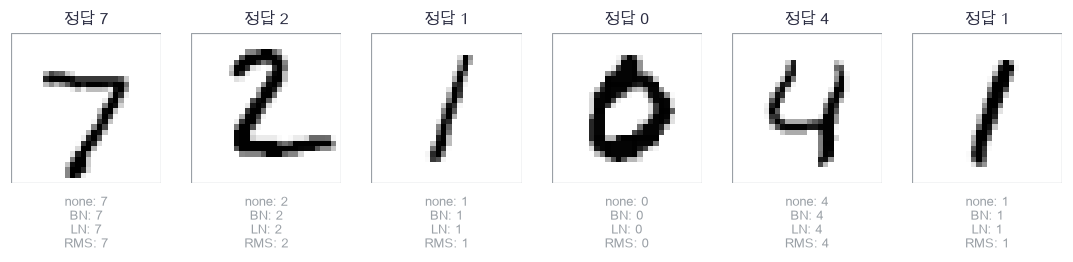

In [59]:
plot_norm_predictions(mnist_test_x[:6].reshape(6, 28, 28), mnist_test_y[:6], test_predictions, norm_names)

In [60]:
# 쓰는 것: trained_models, classifier_forward, mnist_test_x (5절)
bn_final_params, bn_final_state = trained_models["BN"]
mean_before_eval = bn_final_state["mean"].copy()
variance_before_eval = bn_final_state["variance"].copy()
full_eval, _ = classifier_forward(mnist_test_x[:9], bn_final_params, "BN", bn_final_state, training=False)
single_eval, _ = classifier_forward(mnist_test_x[:1], bn_final_params, "BN", bn_final_state, training=False)
np.testing.assert_allclose(full_eval[0], single_eval[0], atol=1e-12)  # 검산: BN eval은 함께 평가하는 표본 수에 의존하지 않습니다.
np.testing.assert_array_equal(bn_final_state["mean"], mean_before_eval)  # 검산: 평가로 저장 평균이 바뀌지 않습니다.
np.testing.assert_array_equal(bn_final_state["variance"], variance_before_eval)  # 검산: 평가로 저장 분산이 바뀌지 않습니다.
print("학습된 BN의 평가 배치 독립성·상태 불변 검산 통과")

학습된 BN의 평가 배치 독립성·상태 불변 검산 통과


🔍 **해석의 범위**

네 방식의 실제 순서는 위 표를 읽습니다. 이 실험은 단일 초기화·자료 부분집합·배치 크기·학습률의 결과입니다. 정규화마다 더 적합한 학습률이 있을 수 있고, 구조와 자료가 달라지면 결과도 달라집니다. “이 방식은 언제나 학습을 빠르게 한다”거나 “특정 설명 하나 때문에 좋아졌다”는 결론까지 이 표에서 얻을 수는 없습니다.

직접 변형할 때는 먼저 validation에서 배치 크기 16과 64를 비교해 보세요. 같은 epoch라도 갱신 횟수가 달라집니다. BN의 통계 묶음과 EMA 갱신 횟수도 함께 달라지므로 한 요인만 바뀌었다고 단정하지 않습니다. test를 반복해 보고 설정을 고르면 더 이상 최종 성능 확인용 독립 자료가 아닙니다.

### ✏️ 연습 5 · 분류 손실의 평균

`log_probs`는 `(N,K)` 로그 확률이고 `labels`는 `(N,)` 정답 클래스 번호입니다. 정답 칸의 음의 로그 평균 한 줄을 채우세요.

In [61]:
def exercise_mean_cross_entropy(log_probs, labels):
    """각 표본의 정답 클래스 로그 확률로 평균 손실을 구합니다."""
    rows = np.arange(len(labels))
    raise NotImplementedError
    return loss

In [62]:
def check_mean_cross_entropy(candidate):
    """정답 확률이 1/2와 1/4인 두 표본의 손실을 검사합니다."""
    probabilities = np.array([[0.5, 0.5], [0.75, 0.25]])
    result = candidate(np.log(probabilities), np.array([0, 1]))
    np.testing.assert_allclose(result, 1.5 * np.log(2))  # 검산: (log2+log4)/2=1.5log2입니다.
run_check(check_mean_cross_entropy, exercise_mean_cross_entropy)

☐ exercise_mean_cross_entropy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = -np.mean(log_probs[rows, labels])
```

</details>

## ✏️ 전체 연결 연습 A–D

작은 배열만으로 정규화의 분모·affine 기울기·RMS의 입력 경로·저장 통계를 다시 확인합니다. 아래 검사는 긴 학습에 의존하지 않습니다.

### ✏️ 연습 A · epsilon을 넣는 위치

중심화한 `centered`, 분산 `variance`, 양수 `epsilon`이 주어집니다. 분산과 ε를 더한 뒤 제곱근으로 나누는 한 줄을 채우세요.

In [63]:
def exercise_epsilon_denominator(centered, variance, epsilon):
    """epsilon을 제곱근 안에 넣어 정규화합니다."""
    raise NotImplementedError
    return normalized

In [64]:
def check_epsilon_denominator(candidate):
    """분산 4와 epsilon 5이면 분모가 3임을 검사합니다."""
    result = candidate(np.array([[-2., 2.]]), np.array([[4.]]), 5.)
    np.testing.assert_allclose(result, [[-2 / 3, 2 / 3]])  # 검산: sqrt(4+5)=3이며 sqrt(4)+5가 아닙니다.
run_check(check_epsilon_denominator, exercise_epsilon_denominator)

☐ exercise_epsilon_denominator: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
normalized = centered / np.sqrt(variance + epsilon)
```

</details>

### ✏️ 연습 B · 학습 가능한 배율과 이동

출력 기울기 `dy`와 affine 전 정규화 값 `normalized`는 `(N,D)`입니다. 특징별 `dgamma`, `dbeta`를 두 줄로 채우세요.

In [65]:
def exercise_affine_gradients(dy, normalized):
    """표본 축으로 합해 특징별 affine 파라미터의 기울기를 구합니다."""
    raise NotImplementedError
    return dgamma, dbeta

In [66]:
def check_affine_gradients(candidate):
    """서로 다른 특징별 합을 손계산한 값으로 검사합니다."""
    dg, db = candidate(np.array([[1., 2.], [3., 4.]]), np.array([[-1., 1.], [1., -1.]]))
    np.testing.assert_allclose(dg, [2., -2.])  # 검산: -1+3=2, 2-4=-2입니다.
    np.testing.assert_allclose(db, [4., 6.])  # 검산: 1+3=4, 2+4=6입니다.
run_check(check_affine_gradients, exercise_affine_gradients)

☐ exercise_affine_gradients: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dgamma = np.sum(dy * normalized, axis=0)
dbeta = np.sum(dy, axis=0)
```

</details>

### ✏️ 연습 C · RMS의 직접 경로와 크기 경로

`g=dy*gamma`, `normalized=x*inverse`가 이미 계산되어 있습니다. 특징 축의 평균을 사용해 RMS 입력 기울기 한 줄을 채우세요.

In [67]:
def exercise_rms_backward(g, normalized, inverse):
    """RMS 직접 경로에서 크기 변화가 주는 기여를 뺍니다."""
    raise NotImplementedError
    return dx

In [68]:
def check_rms_backward(candidate):
    """첫째 특징의 크기 경로와 둘째 특징의 직접 경로를 함께 검사합니다."""
    result = candidate(np.array([[2., 3.]]), np.array([[1., 0.]]), np.array([[0.5]]))
    np.testing.assert_allclose(result, [[0.5, 1.5]])  # 검산: 평균(g·정규화)=1이므로 0.5·([2,3]-[1,0])입니다.
run_check(check_rms_backward, exercise_rms_backward)

☐ exercise_rms_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dx = inverse * (g - normalized * np.mean(g * normalized, axis=1, keepdims=True))
```

</details>

### ✏️ 연습 D · 저장 통계의 갱신 비율

기존 통계 `running`, 새 배치 통계 `batch_stat`, 새 값의 비중 `alpha`를 받습니다. EMA 한 줄을 채우세요.

In [69]:
def exercise_running_average(running, batch_stat, alpha):
    """기존 통계와 새 배치 통계를 정해 둔 비율로 섞습니다."""
    raise NotImplementedError
    return updated

In [70]:
def check_running_average(candidate):
    """새 값 20%를 반영할 때 두 좌표의 결과를 검사합니다."""
    result = candidate(np.array([0., 10.]), np.array([5., 0.]), 0.2)
    np.testing.assert_allclose(result, [1., 8.])  # 검산: 0.8·[0,10]+0.2·[5,0]=[1,8]입니다.
run_check(check_running_average, exercise_running_average)

☐ exercise_running_average: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updated = (1 - alpha) * running + alpha * batch_stat
```

</details>

## ✏️ 다음 단계 준비도

**설명 확인:** BN·LN·RMS가 묶는 값과 평균 제거 유무를 설명할 수 있나요? BN에서 학습 통계와 평가 통계를 나누는 이유는 무엇인가요? 저장 통계가 학습 가능한 γ·β와 어떻게 다른가요?

**수식 확인:** $v/(v+\epsilon)$을 직접 유도할 수 있나요? BN·LN의 입력 기울기에서 직접 경로, 평균 경로, 분산 경로를 찾을 수 있나요? LN에서 γ를 먼저 곱한 뒤 평균해야 하는 이유를 설명할 수 있나요?

**구현 확인:** `(N,D)`에서 통계 shape와 γ·β shape를 써 볼 수 있나요? CNN `(N,C,H,W)`의 채널별 BN과 토큰 `(N,T,D)`의 마지막 축 LN을 구분할 수 있나요? eval 호출이 BN 상태를 바꾸지 않는지 검사할 수 있나요?

**변형 검산:** 상수 입력·영 입력·BN 배치 1·LN 특징 1에서 출력과 입력 기울기가 어떻게 되는지 예측할 수 있나요? 입력을 세 배로 만들 때 ε도 어떻게 바꾸면 정확히 같은 결과가 되는지 말할 수 있나요? 통계를 수치미분 도중 갱신하면 검사 대상 함수가 왜 바뀌나요?

다음에는 [17 ResNet](17_resnet.ipynb)에서 정규화와 별개로 입력을 더하는 경로가 미분에 무엇을 추가하는지 봅니다. [18 U-Net](18_unet.ipynb)에서는 공간 크기를 맞추고 여러 해상도의 특징을 합칩니다. 여기에 정규화를 추가하는 변형을 만들 때에는 이 노트북의 축 구분을 다시 적용할 수 있습니다.

📎 **원문과 연결**

[Batch Normalization 원문](https://arxiv.org/abs/1502.03167), [Layer Normalization 원문](https://arxiv.org/abs/1607.06450), [RMSNorm 원문](https://arxiv.org/abs/1910.07467)은 세 방법의 출발점입니다. 이 노트북은 2차원 배열과 명시한 ε·EMA 규약으로 계산을 구성한 교육용 구현입니다. 더 큰 구조나 특정 프레임워크와 비교할 때는 통계 축, affine 변수, 분산 추정, 저장 통계 갱신 규약을 각각 확인해야 합니다.